# Hopkins imaging: transmission cross coefficients and SOCS

`LithoSimulation` images a mask with **Abbe's method**: every source point
illuminates the mask, its diffraction orders pass the pupil, and the
intensities are summed over the source. A new mask means a new source
integration. **Hopkins' method** does the source integration first. If the
mask diffracts the same way for every source point (the *Hopkins
approximation*), the image of a periodic mask with orders $a_o$ is

$$ I(\mathbf r) = \sum_{o,o'} a_o\,a_{o'}^*\,\mathrm{TCC}(o, o')\,e^{i(\mathbf f_o - \mathbf f_{o'})\cdot\mathbf r},
\qquad
\mathrm{TCC}(o, o') = \sum_{s} w_s \sum_{\text{pol., } i} H_{o,i}(s)\,H_{o',i}^*(s), $$

where $H_{o,i}(s)$ is field component $i$ in the image that a unit order $o$
produces for source point $s$: pupil, aberrations, defocus, vectorial
polarization transfer and wafer stack. The **transmission cross
coefficients** describe the optics only; once computed they image any
layout with the same pitch.

The TCC is Hermitian and positive semidefinite. Its eigenvectors $\phi_k$
(eigenvalues $\lambda_k$) turn the image into a **sum of coherent systems
(SOCS)**,

$$ I(\mathbf r) = \sum_k \lambda_k \Big|\sum_o a_o\,\phi_k(o)\,e^{i\mathbf f_o\cdot\mathbf r}\Big|^2, $$

and a few kernels usually carry nearly all of the energy. This is the engine
of fast OPC, inverse lithography and source mask optimization.

`pyoptics.litho.hopkins` builds the TCC from the same pupil and polarization
code as the Abbe engine. This notebook covers:

1. The TCC as a matrix, for different sources.
2. Agreement with Abbe: exact for thin masks, approximate for film masks.
3. SOCS: eigenvalue spectra and the kernels.
4. Convergence of truncated SOCS in intensity and CD.
5. Speed: many masks with the same optics.
6. An application: sizing contact holes by a bias search.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.litho import (Illumination, MaskLayout, ThinMask, FilmMask, Projector, LithoSimulation,
                            hopkins, metrics)

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})

WL, NA, N_WATER = 193.0, 1.35, 1.437
water = Projector(NA, WL, n=N_WATER)

## 1. The TCC as a matrix

For a 1D mask the orders are $f_m = 2\pi m/p$, and the TCC is a matrix over
pairs of orders. A large pitch (here 1500 nm) samples it finely. Entry
$(m, m')$ says how strongly orders $m$ and $m'$ interfere in the image. The
two orders must pass the pupil for the same source point. For a small
source this holds for every pair of orders inside the pupil: the TCC is
nearly the outer product of the pupil with itself, a full square (the
coherent limit, rank 1). A large source lets orders up to $|f| = 1 + \sigma$
contribute, but two orders pass together only if they are less than the
pupil diameter apart, so the support becomes a band around the diagonal
whose weight falls off away from it. Off-axis sources concentrate the
weight in off-diagonal lobes.

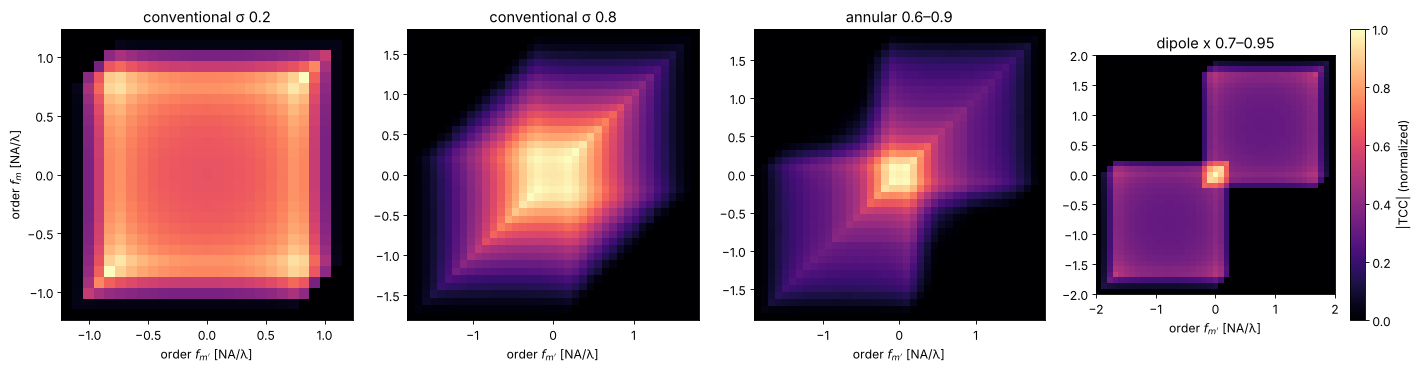

In [2]:
pitch = 1500.0
iso = MaskLayout.lines_spaces(pitch, 90.0)
sources = {"conventional σ 0.2": Illumination.conventional(0.2, polarization="y"),
           "conventional σ 0.8": Illumination.conventional(0.8, polarization="y"),
           "annular 0.6–0.9": Illumination.annular(0.9, 0.6, polarization="y"),
           "dipole x 0.7–0.95": Illumination.dipole(0.95, 0.7, polarization="y")}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (name, ill) in zip(axes, sources.items()):
    tcc = hopkins.TCC(LithoSimulation(iso, ThinMask.binary(), ill, water))
    f = tcc.f_x/(2*np.pi/WL*NA)  # in units of NA/λ (pupil radius = 1)
    T = np.abs(tcc.matrix[0])
    im = ax.imshow(T/T.max(), extent=(f[0], f[-1], f[0], f[-1]), cmap="magma", vmin=0, vmax=1)
    ax.set_title(name); ax.set_xlabel("order $f_{m'}$ [NA/λ]")
axes[0].set_ylabel("order $f_m$ [NA/λ]")
plt.colorbar(im, ax=axes[-1], label="|TCC| (normalized)")
fig.tight_layout()

The diagonal $\mathrm{TCC}(m, m)$ is the light that order $m$ alone
carries to the image: it is the fraction of the source for which the order
passes, 1 inside $|f| \le 1 - \sigma$ and 0 beyond $|f| = 1 + \sigma$. The
dipole couples the zero order (centre) with orders up to $|f| \approx 1.65$
(the off-diagonal blocks): interference of the zero order with a first
order that far out is what images the densest pitches.

## 2. Agreement with Abbe

For a `ThinMask` the transmissions do not depend on the angle of incidence,
so Hopkins and Abbe are the same sum in a different order: the images agree
to rounding error, including vectorial imaging, polarized sources,
aberrations, defocus and a wafer stack. A `FilmMask` computes its
transmissions for each angle of incidence at the mask; the TCC uses those at
normal incidence (the Hopkins approximation), which leaves a small error
because the angles at the mask are only up to $\mathrm{NA}\,\sigma/4$.

thin att. PSM: Abbe 3 ms, TCC 1 ms, orders (5, 5), max difference 8.3e-17
MoSi film mask: Abbe 4 ms, TCC 2 ms, orders (5, 5), max difference 1.3e-03


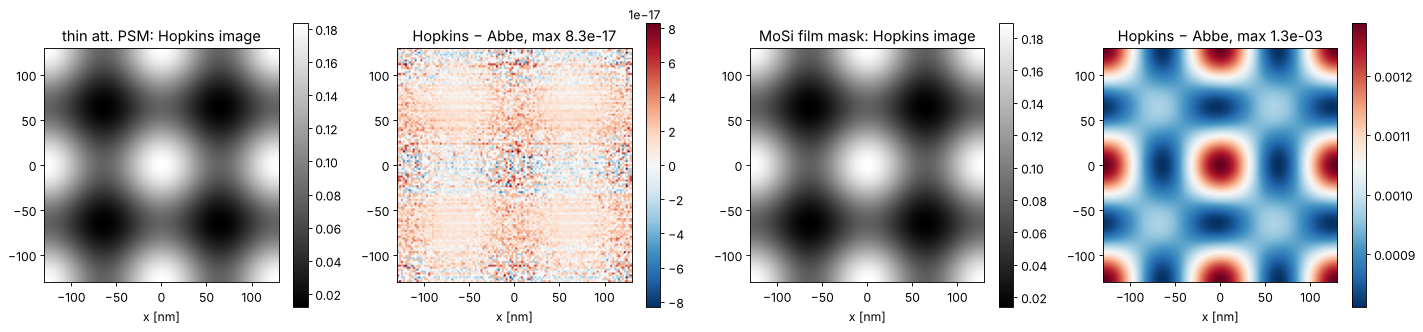

In [3]:
holes = MaskLayout.contact_holes(130.0, 65.0)
quasar = Illumination.quasar(0.95, 0.7, polarization="TE")
aberrated = water.with_(zernikes={7: 0.03, 9: 0.02})
x = np.linspace(-130, 130, 121)
y = np.linspace(-130, 130, 121)
mosi = FilmMask([2.343], [0.586], [68.0], name="MoSi 68 nm")
rows = []
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for k, (stack, name) in enumerate(((ThinMask.att_psm(0.06), "thin att. PSM"), (mosi, "MoSi film mask"))):
    sim = LithoSimulation(holes, stack, quasar, aberrated)
    t0 = time.perf_counter(); I_abbe = sim.image(x, y, focus=40.0); t_abbe = time.perf_counter() - t0
    t0 = time.perf_counter(); tcc = hopkins.TCC(sim, [40.0]); t_tcc = time.perf_counter() - t0
    I_hop = tcc.image(x, y)[0]
    im = axes[2*k].imshow(I_hop, extent=(x[0], x[-1], y[0], y[-1]), cmap="gray")
    axes[2*k].set_title(f"{name}: Hopkins image")
    plt.colorbar(im, ax=axes[2*k])
    im = axes[2*k + 1].imshow(I_hop - I_abbe, extent=(x[0], x[-1], y[0], y[-1]), cmap="RdBu_r")
    axes[2*k + 1].set_title(f"Hopkins − Abbe, max {np.abs(I_hop - I_abbe).max():.1e}")
    plt.colorbar(im, ax=axes[2*k + 1])
    print(f"{name}: Abbe {1000*t_abbe:.0f} ms, TCC {1000*t_tcc:.0f} ms, orders {tcc.shape[:2]}, "
          f"max difference {np.abs(I_hop - I_abbe).max():.1e}")
for ax in axes:
    ax.set_xlabel("x [nm]")
fig.tight_layout()

For the film mask the difference is a few $10^{-3}$ of the clear field
intensity, located at the edges of the holes. The size of this error is
what decides whether a production flow can use Hopkins for a given mask
stack.

## 3. SOCS: eigenvalues and kernels

The eigenvalues fall off quickly for a small coherent source: a single
source point with one polarization state gives a TCC of rank 1 in the
scalar model (rank 3 with the vectorial field components). Larger and
more structured sources need more kernels. The kernels themselves, as
coherent amplitude point spread functions in real space, show how the
system "sees": the first kernel is a blurred spot, the following ones have
the symmetries of the source (here the four poles of a quasar).

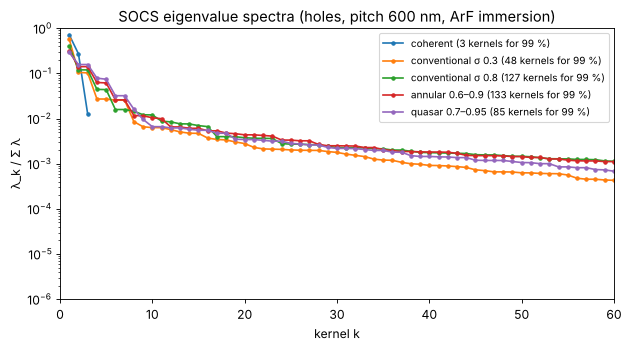

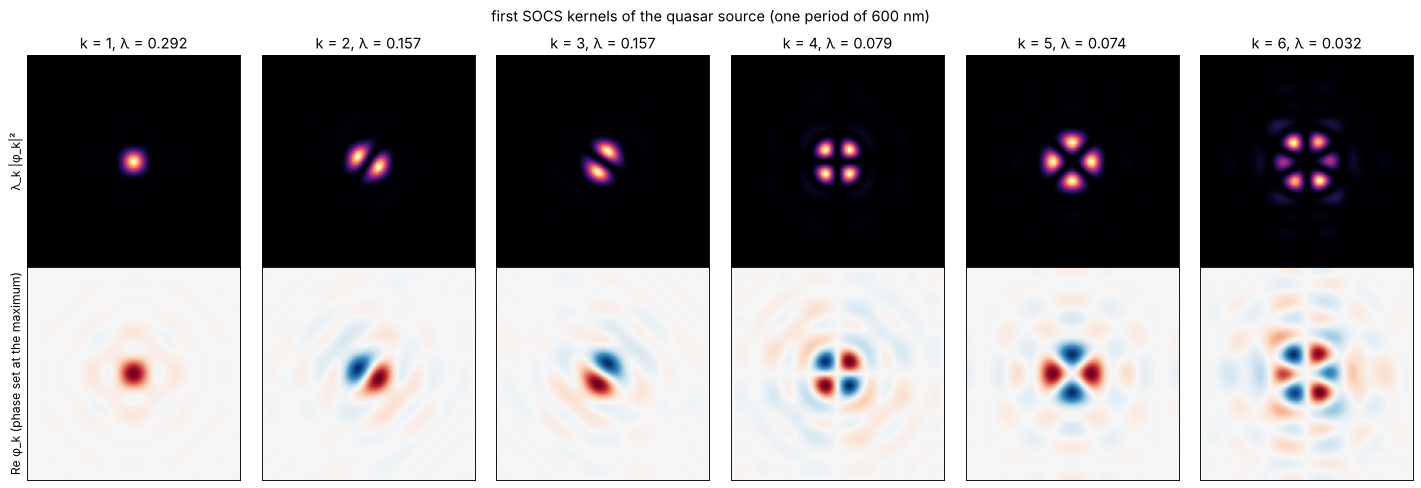

In [4]:
holes2d = MaskLayout.contact_holes(600.0, 80.0)  # large pitch: fine sampling of the kernels
spectra = {"coherent": Illumination.coherent(polarization="x"),
           "conventional σ 0.3": Illumination.conventional(0.3, polarization="TE"),
           "conventional σ 0.8": Illumination.conventional(0.8, polarization="TE"),
           "annular 0.6–0.9": Illumination.annular(0.9, 0.6, polarization="TE"),
           "quasar 0.7–0.95": Illumination.quasar(0.95, 0.7, polarization="TE")}
fig, ax = plt.subplots(figsize=(8, 4.5))
socs_all = {}
for name, ill in spectra.items():
    tcc = hopkins.TCC(LithoSimulation(holes2d, ThinMask.binary(), ill, water))
    socs_all[name] = s = tcc.socs()
    lam = s.eigenvalues[0]/s.eigenvalues[0].sum()
    ax.semilogy(np.arange(1, len(lam) + 1), lam, ".-", label=f"{name} ({np.searchsorted(np.cumsum(lam), 0.99) + 1} kernels for 99 %)")
ax.set_xlim(0, 60); ax.set_ylim(1e-6, 1)
ax.set_xlabel("kernel k"); ax.set_ylabel("λ_k / Σ λ"); ax.legend(fontsize=9)
ax.set_title("SOCS eigenvalue spectra (holes, pitch 600 nm, ArF immersion)")
fig.tight_layout()

xk = np.linspace(-300, 300, 151)
K = socs_all["quasar 0.7–0.95"].kernel_fields(xk, xk)
# kernels have an arbitrary global phase: make each one real at its largest value
K = K*np.exp(-1j*np.angle(K.reshape(len(K), -1)[np.arange(len(K)), np.abs(K.reshape(len(K), -1)).argmax(axis=1)]))[:, None, None]
lam = socs_all["quasar 0.7–0.95"].eigenvalues[0]
fig, axes = plt.subplots(2, 6, figsize=(18, 6.2))
for k in range(6):
    for row, (data, cmap) in enumerate(((np.abs(K[k])**2*lam[k], "magma"), (K[k].real, "RdBu_r"))):
        a = axes[row, k]
        if row == 1:
            v = np.abs(K[k]).max()
            a.imshow(data, extent=(xk[0], xk[-1], xk[0], xk[-1]), cmap=cmap, vmin=-v, vmax=v)
        else:
            a.imshow(data, extent=(xk[0], xk[-1], xk[0], xk[-1]), cmap=cmap)
        a.set_xticks([]); a.set_yticks([])
    axes[0, k].set_title(f"k = {k + 1}, λ = {lam[k]/lam.sum():.3f}")
axes[0, 0].set_ylabel("λ_k |φ_k|²"); axes[1, 0].set_ylabel("Re φ_k (phase set at the maximum)")
fig.suptitle("first SOCS kernels of the quasar source (one period of 600 nm)")
fig.tight_layout()

## 4. Truncated SOCS: how many kernels?

The image error of truncated SOCS shrinks with the energy of the dropped
kernels, but what matters for lithography is the printed CD. Dense contact
holes (65 nm at 130 nm pitch, att. PSM, quasar) have only 5 × 5 orders,
and the TCC has 9 nonzero eigenvalues:

9 kernels in total; CD error below 0.1 nm from 8 kernels on


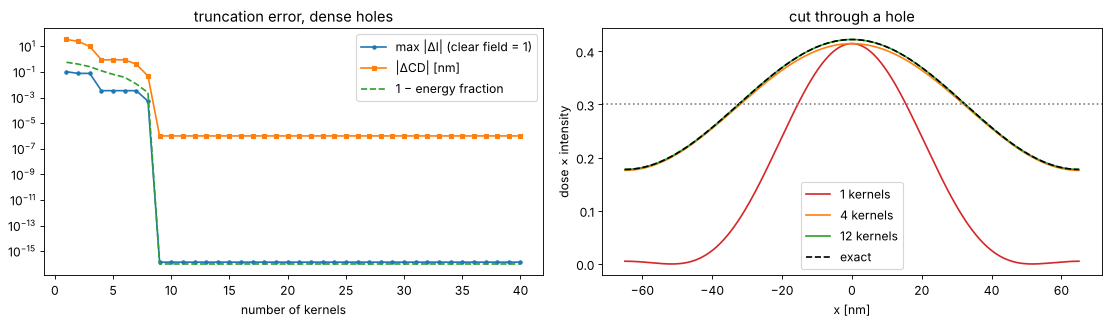

In [5]:
sim = LithoSimulation(holes, ThinMask.att_psm(0.06), quasar, water)
tcc = hopkins.TCC(sim)
socs = tcc.socs()
u = np.linspace(-65, 65, 401)
exact = tcc.image(u)[0]
D = metrics.dose_to_size(u, exact, 65.0, 0.3)
cd_exact = metrics.threshold_cd(u, D*exact, 0.3, bright=True)
ks = np.arange(1, 41)
err_I, err_cd, energy = [], [], []
for k in ks:
    s = tcc.socs(n_kernels=k)
    I = s.image(u)[0]
    err_I.append(np.abs(I - exact).max())
    err_cd.append(abs(metrics.threshold_cd(u, D*I, 0.3, bright=True) - cd_exact))
    energy.append(s.energy[0])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].semilogy(ks, err_I, "o-", ms=3, label="max |ΔI| (clear field = 1)")
axes[0].semilogy(ks, np.array(err_cd) + 1e-6, "s-", ms=3, label="|ΔCD| [nm]")
axes[0].semilogy(ks, 1 - np.array(energy) + 1e-16, "--", label="1 − energy fraction")
axes[0].set_xlabel("number of kernels"); axes[0].legend(); axes[0].set_title("truncation error, dense holes")
for k, c in ((1, "C3"), (4, "C1"), (12, "C2")):
    axes[1].plot(u, D*tcc.socs(n_kernels=k).image(u)[0], color=c, label=f"{k} kernels")
axes[1].plot(u, D*exact, "k--", label="exact")
axes[1].axhline(0.3, color="gray", ls=":")
axes[1].set_xlabel("x [nm]"); axes[1].set_ylabel("dose × intensity"); axes[1].legend()
axes[1].set_title("cut through a hole")
fig.tight_layout()
print(f"{socs.n_kernels} kernels in total; CD error below 0.1 nm from {ks[np.argmax(np.array(err_cd) < 0.1)]} kernels on")

## 5. Speed: many masks with the same optics

Hopkins pays off when the optics stay fixed and the mask changes: OPC
iterations, mask biasing, many clips under one illumination. The time for
the TCC is spent once. Below: a 1 µm × 1 µm clip with several features
(31 × 31 orders), imaged on a 129 × 129 grid for 20 small variations of
the features.

source points: 108, orders: 31 x 31
Abbe:              1.99 s for 20 masks
TCC:               0.05 s once, then   0.43 s for 20 masks (max error 1.9e-16)
SOCS (173 kernels):   0.59 s once, then   1.85 s (max error 1.5e-04)


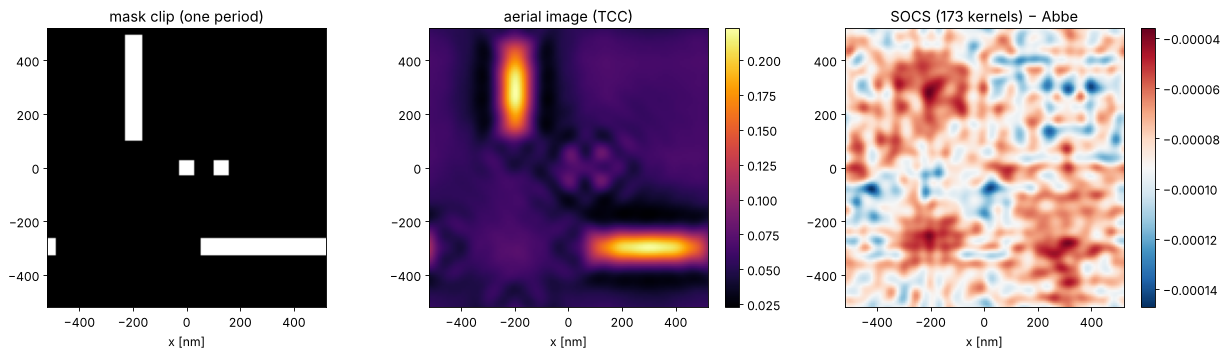

In [6]:
def clip(bias):
    feats = [(0.0, 0.0, 65 + bias, 65 + bias), (130.0, 0.0, 65 + bias, 65 + bias),
             (-200.0, 300.0, 65 + bias, 400.0), (300.0, -300.0, 500.0, 65 + bias)]
    return MaskLayout(1040.0, 1040.0, features=feats, tone="dark")

ill = Illumination.quasar(0.95, 0.7, polarization="TE", n_samples=31)
sim = LithoSimulation(clip(0.0), ThinMask.att_psm(0.06), ill, water)
xg = np.linspace(-520, 520, 129)
biases = np.linspace(-6, 6, 20)

t0 = time.perf_counter()
abbe = [sim.with_(layout=clip(b)).image(xg, xg) for b in biases]
t_abbe = time.perf_counter() - t0

t0 = time.perf_counter(); tcc = hopkins.TCC(sim); t_tcc = time.perf_counter() - t0
t0 = time.perf_counter(); hop = [tcc.image(xg, xg, layout=clip(b))[0] for b in biases]; t_hop = time.perf_counter() - t0
t0 = time.perf_counter(); socs = tcc.socs(energy=0.995); t_eig = time.perf_counter() - t0
t0 = time.perf_counter(); soc = [socs.image(xg, xg, layout=clip(b))[0] for b in biases]; t_socs = time.perf_counter() - t0

print(f"source points: {len(ill.s_x)}, orders: {tcc.shape[0]} x {tcc.shape[1]}")
print(f"Abbe:            {t_abbe:6.2f} s for {len(biases)} masks")
print(f"TCC:             {t_tcc:6.2f} s once, then {t_hop:6.2f} s for {len(biases)} masks "
      f"(max error {max(np.abs(a - h).max() for a, h in zip(abbe, hop)):.1e})")
print(f"SOCS ({socs.n_kernels} kernels): {t_eig:6.2f} s once, then {t_socs:6.2f} s "
      f"(max error {max(np.abs(a - s).max() for a, s in zip(abbe, soc)):.1e})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ext = (xg[0], xg[-1], xg[0], xg[-1])
axes[0].imshow(clip(0.0).transmission(xg, xg), extent=ext, cmap="gray")
axes[0].set_title("mask clip (one period)")
im = axes[1].imshow(hop[len(biases)//2], extent=ext, cmap="inferno"); plt.colorbar(im, ax=axes[1])
axes[1].set_title("aerial image (TCC)")
im = axes[2].imshow(soc[len(biases)//2] - abbe[len(biases)//2], extent=ext, cmap="RdBu_r"); plt.colorbar(im, ax=axes[2])
axes[2].set_title(f"SOCS ({socs.n_kernels} kernels) − Abbe")
for a in axes:
    a.set_xlabel("x [nm]")
fig.tight_layout()

In this representation (orders of one period, image synthesized from the
mutual intensities of the orders) the full TCC image is already the fastest
way to image a new mask, faster than the truncated SOCS sum. SOCS earns its
place elsewhere: its kernels are the starting point for large non-periodic
layouts imaged by FFT convolution, and its sum of coherent images has
simple gradients with respect to the mask, which is what inverse
lithography and source mask optimization need.

## 6. Application: sizing contact holes by bias

With the TCC, a mask bias search costs milliseconds per step. At a dose
other than the dose to size $D_0$ the holes print at the wrong size; find
the mask bias that prints 65 nm at a few doses by Newton steps on the
printed CD, and check the result with Abbe.

dose 0.85 D0: bias +3.49 nm after 4 Newton steps (5 ms), check with Abbe: 65.000 nm
dose 1.00 D0: bias +0.00 nm after 1 Newton steps (2 ms), check with Abbe: 65.000 nm
dose 1.15 D0: bias -2.80 nm after 4 Newton steps (5 ms), check with Abbe: 65.000 nm


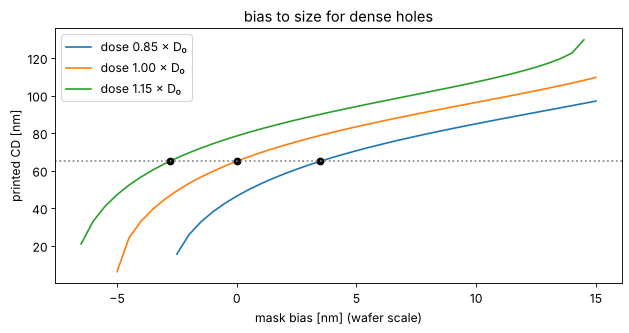

In [7]:
sim = LithoSimulation(holes, ThinMask.att_psm(0.06), quasar, water)
tcc = hopkins.TCC(sim)
u = np.linspace(-65, 65, 401)

def printed_cd(bias, dose):
    I = tcc.image(u, layout=holes.scaled(bias=bias))[0]
    return metrics.threshold_cd(u, dose*I, 0.3, bright=True)

D0 = metrics.dose_to_size(u, tcc.image(u)[0], 65.0, 0.3)
fig, ax = plt.subplots(figsize=(8, 4.3))
b_axis = np.linspace(-10, 15, 51)
for dose in (0.85*D0, D0, 1.15*D0):
    ax.plot(b_axis, [printed_cd(b, dose) for b in b_axis], label=f"dose {dose/D0:.2f} × D₀")
    b, steps = 0.0, 0
    t0 = time.perf_counter()
    for steps in range(1, 20):
        cd = printed_cd(b, dose)
        slope = (printed_cd(b + 0.5, dose) - printed_cd(b - 0.5, dose))/1.0  # MEEF-like slope
        b -= (cd - 65.0)/slope
        if abs(cd - 65.0) < 0.01:
            break
    ax.plot(b, 65.0, "ko")
    print(f"dose {dose/D0:.2f} D0: bias {b:+.2f} nm after {steps} Newton steps "
          f"({1000*(time.perf_counter() - t0):.0f} ms), check with Abbe: "
          f"{sim.with_(layout=holes.scaled(bias=b)).cd(0.3, dose):.3f} nm")
ax.axhline(65.0, color="gray", ls=":")
ax.set_xlabel("mask bias [nm] (wafer scale)"); ax.set_ylabel("printed CD [nm]"); ax.legend()
ax.set_title("bias to size for dense holes")
fig.tight_layout()

The slope of these curves is the MEEF; its value above 1 is the reason why
the Newton steps need a few iterations rather than one. The same loop over
the edges of many features is model based OPC.

## Summary

- `hopkins.TCC(sim, foci)` computes the transmission cross coefficients
  for the illumination, projector, wafer stack and foci of a simulation,
  over the orders of its pitch; `image()` images any layout with that pitch.
- For thin masks Hopkins equals Abbe to rounding error; for film masks the
  Hopkins approximation (transmissions at normal incidence) leaves errors of
  order $10^{-3}$.
- `socs()` gives the eigen decomposition: eigenvalues fall quickly for
  small coherent sources and more slowly for large and structured ones;
  `energy=` or `n_kernels=` truncate it; for dense holes the CD is within
  0.1 nm with 8 of the 9 kernels.
- Once the TCC is computed, every new mask with the same optics costs
  milliseconds: the basis for the OPC and source optimization items of the
  roadmap.